<a href="https://colab.research.google.com/github/yuliamrg/fork-del-curso-practico-frontend-developer/blob/main/Limpieza_datos_fac_ordenes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Importación de librerias 📚

In [ ]:
import pandas as pd # Manipulación de datos
import matplotlib.pyplot as plt # Generador de gráficas
import seaborn as sns # Generador de gráficas
from google.colab import drive # Conexión con google drive
import os # Manipulación de rutas
from datetime import datetime # Manipulación de fechas

# 2. Extracción de datos 🖼

### Montar el disco de goggle drive

In [ ]:
drive.mount('/gdrive')

Mounted at /gdrive


### Leer los datos

In [ ]:
#Lee los datos de los dos archivos que se desea tratar
ruta = os.path.join('/gdrive', 'MyDrive', 'Planeacion-Mtto', 'INDICADORES', 'looker_studio', 'data_qsystem', 'data_ordenes.xlsx')
data = pd.read_excel(ruta)


### Leer los datos prueba

In [ ]:
#Lee los datos de los dos archivos que se desea tratar
ruta1 = os.path.join('/gdrive', 'MyDrive', 'Planeacion-Mtto', 'INDICADORES', 'looker_studio', 'data_qsystem', 'data_ordenes_pendientes.xlsx')
ruta2 = os.path.join('/gdrive', 'MyDrive', 'Planeacion-Mtto', 'INDICADORES', 'looker_studio', 'data_qsystem', 'data_ordenes_terminadas.xlsx')
frame1 = pd.read_excel(ruta1)
frame2 = pd.read_excel(ruta2)


Concatenar ambos frames

In [ ]:
# Concatena los frames en un mismo frame para el tratamiento de los mismos
frame1 = frame1.reindex(columns=frame2.columns, fill_value=None) # Se asegura de que los índices del frame1 sean los mismos que del frame2 para poder concatenar
data = pd.concat([frame1, frame2], ignore_index=True)

Leer datos de hoja de calculo de google en prueba

In [ ]:
# !pip install --upgrade gspread

# from google.colab import auth
# auth.authenticate_user()

# import gspread
# from google.auth import default
# creds, _ = default()

# gc = gspread.authorize(creds)

# # Open the Google Sheet by its title
# spreadsheet_title = "Your Spreadsheet Title"  # Replace with your sheet's title
# sh = gc.open(spreadsheet_title)

# # Select the worksheet you want to read (default is the first sheet)
# worksheet_title = "Sheet1" # Replace with your sheet's name if different
# worksheet = sh.worksheet(worksheet_title)

# # Get all values from the worksheet as a list of lists
# data = worksheet.get_all_values()

# # Convert the data to a pandas DataFrame
# import pandas as pd
# data = pd.DataFrame(data[1:], columns=data[0])

# 3. Exploracion de los datos 🤿

### Vision Inicial general

In [ ]:
print(data.shape) # Cantidad de filas y columnas
data.head() # Titulos de las columnas y primeros registros

(11870, 22)


,Número,Solicitante / Usuario,Fecha de solicitud,Fecha inicia orden,Descripción,Estado,Equipo,Equipos relacionados,Origen,Tipo de solicitud,...,Ubicación,Tipo de servicio,Última observación,Descripción del trabajo,Horas de trabajo,Fecha fin. T,Fecha finaliza orden,Recibió,Causa de falla,Costo repuesto
0,321624,Leonardo medina / LEONARDO FABIO MEDINA COMETA,2025-02-01 18:55:52,2025-02-01 18:57:18,Recorrido y entrega de cilindros en el servici...,Pendiente,No Aplica,NaN,"Solicitud: 82371, Mantenimiento,",Otros,...,NaN,Mantenimiento,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,321605,Paula Andrea Hurtado / FARMACIA PRINCIPAL SERV...,2025-02-01 12:59:47,2025-02-01 15:50:02,Buena tarde \nSolicito comedidamente la revisi...,Pendiente,No Aplica,NaN,"Solicitud: 82351, Mantenimiento,","mobiliario, gases, varios",...,NaN,Mantenimiento,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,321498,leidy gallego / CENTRAL DE MEZCLAS CAM,2025-02-01 08:21:25,2025-02-01 12:15:56,buenos dias solicito amablemente me colaboren ...,Pendiente,No Aplica,NaN,"Solicitud: 82323, Mantenimiento,",Aire acondicionado y Refrigeración,...,NaN,Mantenimiento,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,321497,DANIELA CORTES / UCI_INTERMEDIO UCI_INTERMEDIO,2025-01-31 11:29:05,2025-02-01 12:15:38,BUEN DIA \nPARA REPORTAR LAVAMANOS TAPADO EN L...,Pendiente,No Aplica,NaN,"Solicitud: 82272, Mantenimiento,",Hidráulica y sanitaria,...,"PRINCIPAL, UCI ADULTOS, UCIN",Mantenimiento,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,321495,HEIDY PINCHAO / HOSPITALIZACION_5 HOSPITALIZAC...,2025-02-01 09:24:02,2025-02-01 12:13:35,Buenos días solicito de su amable colaboración...,Pendiente,No Aplica,NaN,"Solicitud: 82327, Mantenimiento,",Eléctrico y redes,...,"PRINCIPAL, ESTACION 5A, HABITACION 508",Mantenimiento,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Informacion del Data Frame Ver cuales columnas son categoricas y cuales son numericas

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11870 entries, 0 to 11869
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Número                   11870 non-null  int64  
 1   Solicitante / Usuario    11870 non-null  object 
 2   Fecha de solicitud       9916 non-null   object 
 3   Fecha inicia orden       11870 non-null  object 
 4   Descripción              11870 non-null  object 
 5   Estado                   11870 non-null  object 
 6   Equipo                   11870 non-null  object 
 7   Equipos relacionados     0 non-null      float64
 8   Origen                   11870 non-null  object 
 9   Tipo de solicitud        11870 non-null  object 
 10  Responsable              11867 non-null  object 
 11  Sede                     11870 non-null  object 
 12  Ubicación                6593 non-null   object 
 13  Tipo de servicio         11870 non-null  object 
 14  Última observación    

### Describir las caracteristicas de las columnas numericas

In [ ]:
data.describe()

,Número,Equipos relacionados,Horas de trabajo,Costo repuesto
count,11870.000000,0.0,9993.000000,9993.0
mean,296341.861837,NaN,92.745822,0.0
std,66831.279612,NaN,434.676033,0.0
min,7236.000000,NaN,0.000000,0.0
25%,307416.250000,NaN,1.000000,0.0
50%,312280.500000,NaN,60.000000,0.0
75%,316784.750000,NaN,60.000000,0.0
max,321627.000000,NaN,15360.000000,0.0


### Graficar para identificar outsiders en variables numericas

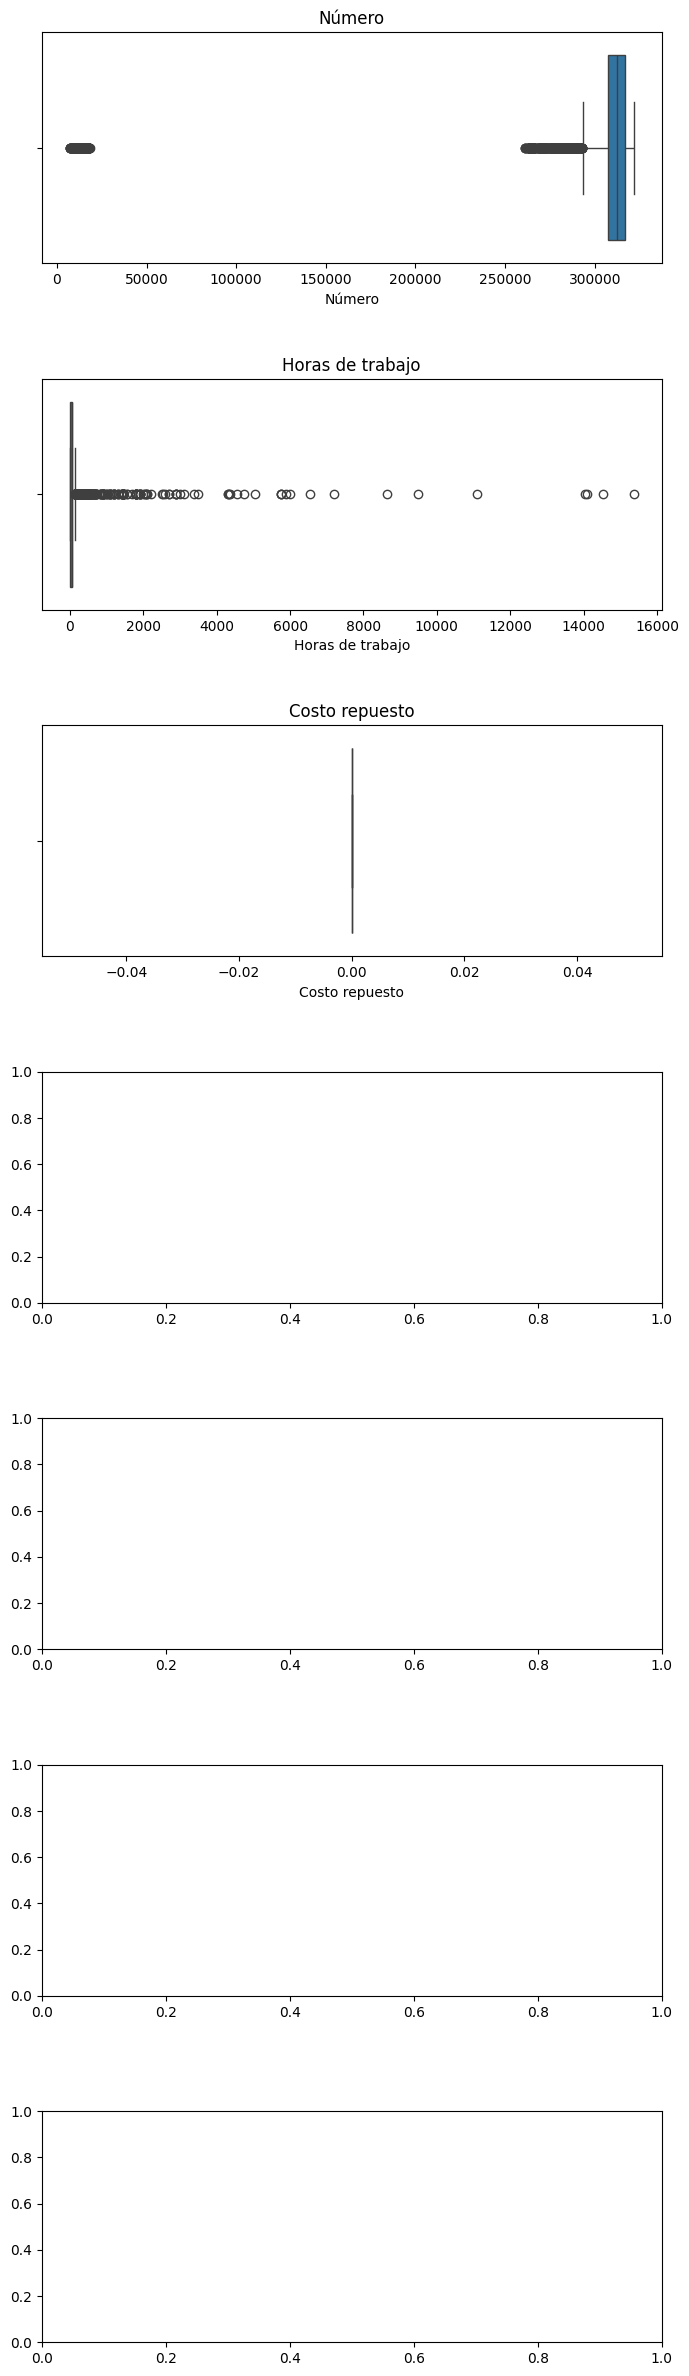

In [ ]:
#Genera plot individual para las variables numericas
cols_num = ['Número', 'Horas de trabajo', 'Costo repuesto']

fig, ax = plt.subplots(nrows=7, ncols=1, figsize=(8,30))
fig.subplots_adjust(hspace=0.5)

for i, col in enumerate(cols_num):
  sns.boxplot(x=col, data=data, ax=ax[i])
  ax[i].set_title(col)

### Revisar cuantos subniveles tienen las columnas categoricas

In [ ]:
cols_cat = ['Estado', 'Equipo', 'Tipo de solicitud', 'Responsable', 'Sede', 'Ubicación', 'Tipo de servicio',
            'Recibió', 'Causa de falla']
for col in cols_cat:
  print(f'Columna {col}: {data[col].nunique()} subniveles')

Columna Estado: 5 subniveles
Columna Equipo: 859 subniveles
Columna Tipo de solicitud: 45 subniveles
Columna Responsable: 246 subniveles
Columna Sede: 40 subniveles
Columna Ubicación: 1459 subniveles
Columna Tipo de servicio: 2 subniveles
Columna Recibió: 1491 subniveles
Columna Causa de falla: 52 subniveles


### Graficar los subniveles por cada variable categorica

<ipython-input-9-70f64928c145>:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(ax[i].get_xticklabels(), rotation=30)
<ipython-input-9-70f64928c145>:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(ax[i].get_xticklabels(), rotation=30)


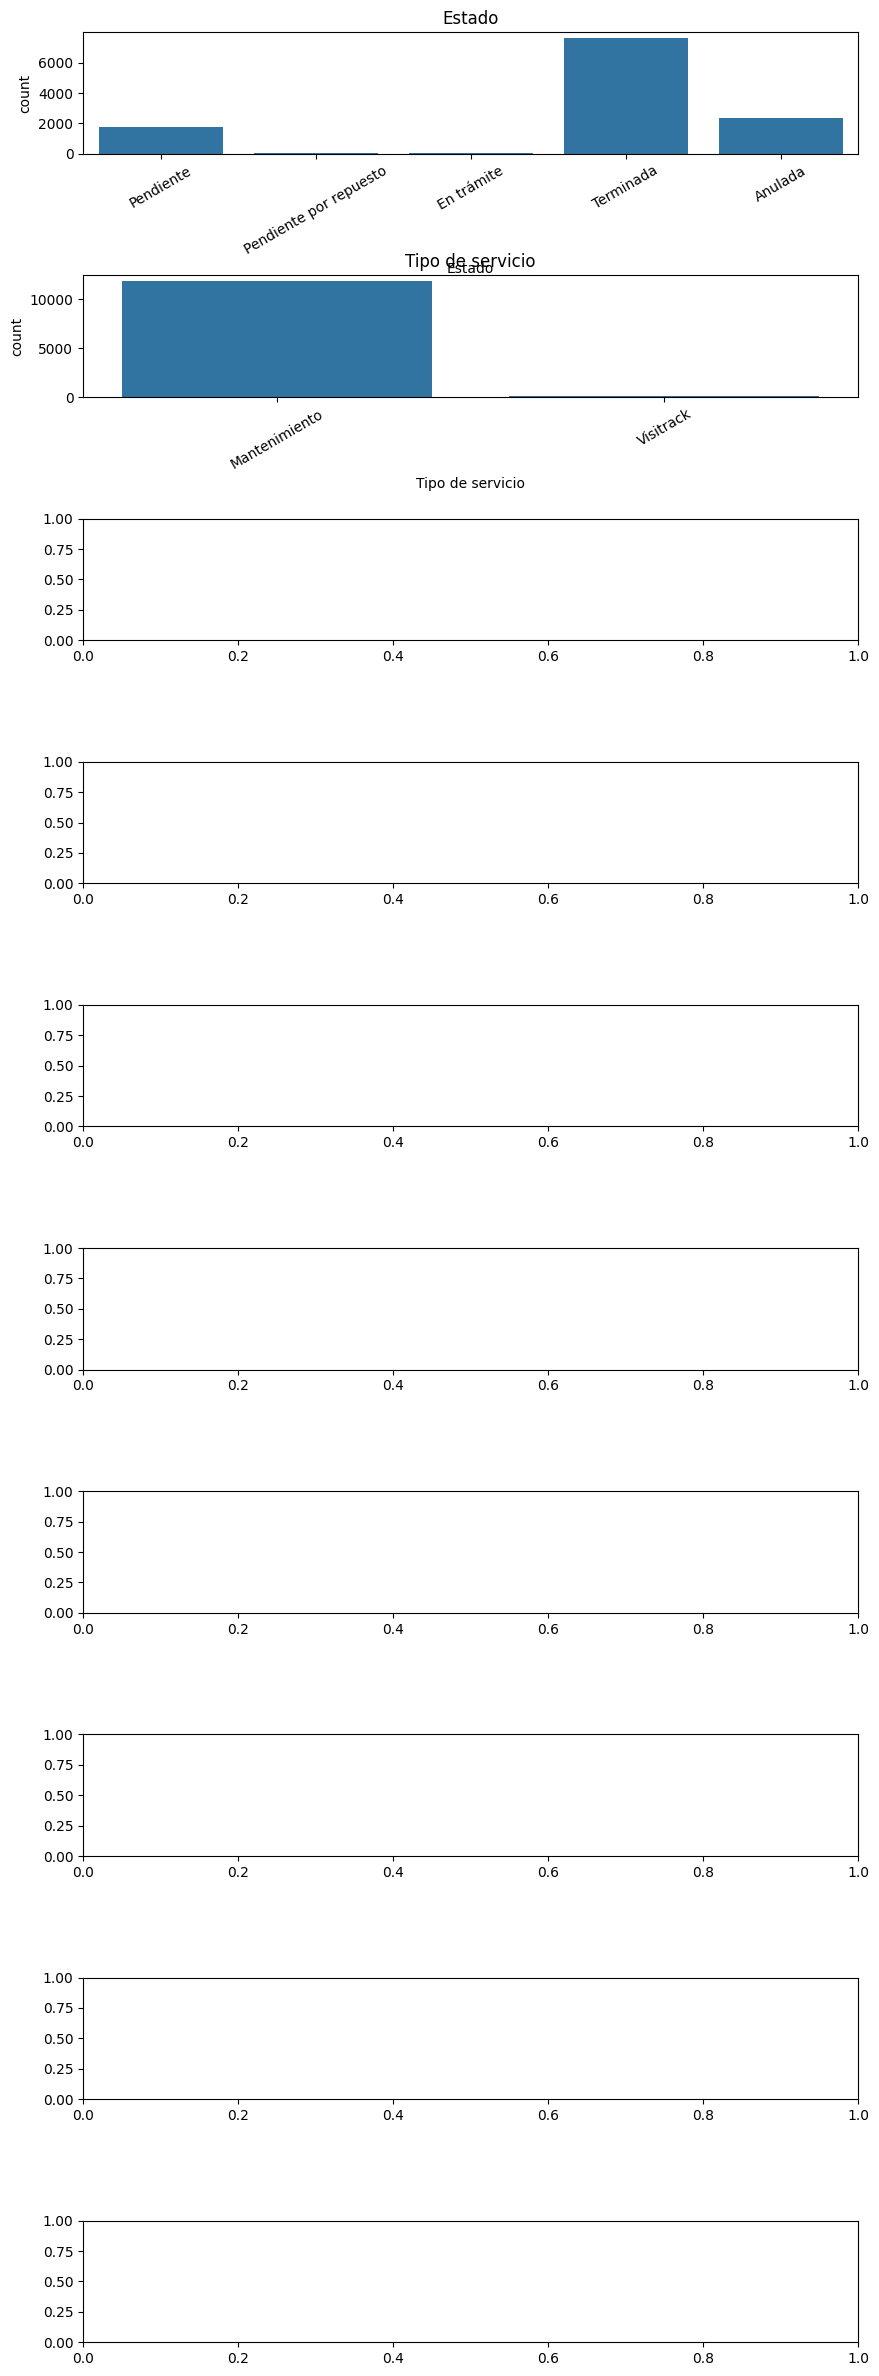

In [ ]:
cols_cat = ['Estado', 'Tipo de servicio']

fig, ax = plt.subplots(nrows=10, ncols=1, figsize=(10,30))
fig.subplots_adjust(hspace=1)

for i, col in enumerate(cols_cat):
  sns.countplot(x=col, data=data, ax=ax[i])
  ax[i].set_title(col)
  ax[i].set_xticklabels(ax[i].get_xticklabels(), rotation=30)

# **4. Limpieza de datos** 🎇

### Borrar fillas exactamente iguales

In [ ]:
print({data.shape})
data.drop_duplicates(inplace=True)
print({data.shape})

{(11870, 22)}
{(11870, 22)}


### Eliminar los espacios en blanco de las columnas

In [ ]:
data.columns = data.columns.str.strip()

### Eliminar columnas completamente vacías

In [ ]:
print("Columnas después de la limpieza:", data.columns, {data.shape})

# Recorrer todas las columnas y eliminar las que están completamente vacías
columnas_vacias = [col for col in data.columns if data[col].isnull().all()]

# Eliminar las columnas vacías
data.drop(columns=columnas_vacias, inplace=True)

# Mostrar las columnas restantes después de la limpieza
print("Columnas eliminadas:", columnas_vacias)
print("Columnas después de la limpieza:", data.columns, {data.shape})

Columnas después de la limpieza: Index(['Número', 'Solicitante / Usuario', 'Fecha de solicitud',
       'Fecha inicia orden', 'Descripción', 'Estado', 'Equipo',
       'Equipos relacionados', 'Origen', 'Tipo de solicitud', 'Responsable',
       'Sede', 'Ubicación', 'Tipo de servicio', 'Última observación',
       'Descripción del trabajo', 'Horas de trabajo', 'Fecha fin. T',
       'Fecha finaliza orden', 'Recibió', 'Causa de falla', 'Costo repuesto'],
      dtype='object') {(11870, 22)}
Columnas eliminadas: ['Equipos relacionados']
Columnas después de la limpieza: Index(['Número', 'Solicitante / Usuario', 'Fecha de solicitud',
       'Fecha inicia orden', 'Descripción', 'Estado', 'Equipo', 'Origen',
       'Tipo de solicitud', 'Responsable', 'Sede', 'Ubicación',
       'Tipo de servicio', 'Última observación', 'Descripción del trabajo',
       'Horas de trabajo', 'Fecha fin. T', 'Fecha finaliza orden', 'Recibió',
       'Causa de falla', 'Costo repuesto'],
      dtype='object') {(1187

### Manejar valores nulos

Verificar columnas con valores nulos

In [ ]:
print("Valores nulos antes de limpieza:")

print(data.isnull().sum())

Valores nulos antes de limpieza:
Número                         0
Solicitante / Usuario          0
Fecha de solicitud          1954
Fecha inicia orden             0
Descripción                    0
Estado                         0
Equipo                         0
Origen                         0
Tipo de solicitud              0
Responsable                    3
Sede                           0
Ubicación                   5277
Tipo de servicio               0
Última observación         10248
Descripción del trabajo     4071
Horas de trabajo            1877
Fecha fin. T                1877
Fecha finaliza orden        1888
Recibió                     6881
Causa de falla              3835
Costo repuesto              1877
dtype: int64


Elimina los valores nulos de las columnas con excepciones para tratarlas de forma particular

In [ ]:
print("Valores nulos antes de limpieza:")
print(data.isnull().sum())

excepciones = ["Fecha de solicitud", "Ubicación", "Última observación", "Descripción del trabajo", "Horas de trabajo",
               "Fecha fin. T", "Fecha finaliza orden", "Recibió", "Causa de falla", "Costo repuesto"]

for columna in data.columns:
    if columna not in excepciones:  # Solo elimina nulos si la columna NO está en la lista de excepciones
        data = data.dropna(subset=[columna])

# Mostrar cantidad de valores nulos después de la limpieza
print("Valores nulos después de limpieza:")
print(data.isnull().sum())


Valores nulos antes de limpieza:
Número                         0
Solicitante / Usuario          0
Fecha de solicitud          1954
Fecha inicia orden             0
Descripción                    0
Estado                         0
Equipo                         0
Origen                         0
Tipo de solicitud              0
Responsable                    3
Sede                           0
Ubicación                   5277
Tipo de servicio               0
Última observación         10248
Descripción del trabajo     4071
Horas de trabajo            1877
Fecha fin. T                1877
Fecha finaliza orden        1888
Recibió                     6881
Causa de falla              3835
Costo repuesto              1877
dtype: int64
Valores nulos después de limpieza:
Número                         0
Solicitante / Usuario          0
Fecha de solicitud          1952
Fecha inicia orden             0
Descripción                    0
Estado                         0
Equipo                      

Reemplazar Valores nulos de 'Fecha de solicitud' por 'fecha inicia orden'

In [ ]:
print("Valores nulos en 'Fecha de solicitud' antes de la limpieza:", data["Fecha de solicitud"].isnull().sum())

# Reemplazar valores nulos usando inplace=True sale un warning
# data["Fecha de solicitud"].fillna(data["Fecha inicia orden"], inplace=True)
# Reemplazar valores nulos sin usar inplace=True para evitar el warning
data["Fecha de solicitud"] = data["Fecha de solicitud"].fillna(data["Fecha inicia orden"])


print("Valores nulos en 'Fecha de solicitud' después de la limpieza:", data["Fecha de solicitud"].isnull().sum())



Valores nulos en 'Fecha de solicitud' antes de la limpieza: 1952
Valores nulos en 'Fecha de solicitud' después de la limpieza: 0


Reemplazar nulos de 'Ubicación' por "No proporcionada"

In [ ]:
print("Valores nulos en 'Ubicación' antes de la limpieza:", data["Ubicación"].isnull().sum())

# Reemplazar valores nulos usando inplace=True sale un warning
# data["Fecha de solicitud"].fillna(data["Fecha inicia orden"], inplace=True)
# Reemplazar valores nulos sin usar inplace=True para evitar el warning
data["Ubicación"] = data["Ubicación"].fillna("No proporcionada")


print("Valores nulos en 'Ubicación' después de la limpieza:", data["Ubicación"].isnull().sum())


Valores nulos en 'Ubicación' antes de la limpieza: 5276
Valores nulos en 'Ubicación' después de la limpieza: 0


Reemplazar nulos de 'Última observación' por "Ninguna"

In [ ]:
print("Valores nulos en 'Última observación' antes de la limpieza:", data["Última observación"].isnull().sum())

data["Última observación"] = data["Última observación"].fillna("Ninguna")

print("Valores nulos en 'Última observación' después de la limpieza:", data["Última observación"].isnull().sum())


Valores nulos en 'Última observación' antes de la limpieza: 10245
Valores nulos en 'Última observación' después de la limpieza: 0


Reemplazar nulos de 'Descripción del trabajo' por "Ninguna"

In [ ]:
print("Valores nulos en 'Descripción del trabajo' antes de la limpieza:", data["Descripción del trabajo"].isnull().sum())

data["Descripción del trabajo"] = data["Descripción del trabajo"].fillna("Ninguna")

print("Valores nulos en 'Descripción del trabajo' después de la limpieza:", data["Descripción del trabajo"].isnull().sum())


Valores nulos en 'Descripción del trabajo' antes de la limpieza: 4068
Valores nulos en 'Descripción del trabajo' después de la limpieza: 0


Reemplazar nulos de 'Horas de trabajo' y 'Costo repuesto' por 0

In [ ]:
print("Valores nulos en 'Horas de trabajo' antes de la limpieza:", data["Horas de trabajo"].isnull().sum())
print("Valores nulos en 'Costo repuesto' antes de la limpieza:", data["Costo repuesto"].isnull().sum())

data["Horas de trabajo"] = data["Horas de trabajo"].fillna(0)
data["Costo repuesto"] = data["Costo repuesto"].fillna(0)

print("Valores nulos en 'Horas de trabajo' después de la limpieza:", data["Horas de trabajo"].isnull().sum())
print("Valores nulos en 'Costo repuesto' después de la limpieza:", data["Costo repuesto"].isnull().sum())


Valores nulos en 'Horas de trabajo' antes de la limpieza: 1877
Valores nulos en 'Costo repuesto' antes de la limpieza: 1877
Valores nulos en 'Horas de trabajo' después de la limpieza: 0
Valores nulos en 'Costo repuesto' después de la limpieza: 0


Reemplazar nulos de 'Fecha fin. T' y 'Fecha finaliza orden' por la fecha actual

In [ ]:
print("Valores nulos en 'Fecha fin. T' antes de la limpieza:", data["Fecha fin. T"].isnull().sum())
print("Valores nulos en 'Fecha finaliza orden' antes de la limpieza:", data["Fecha finaliza orden"].isnull().sum())

fecha_actual = pd.to_datetime("today")
data["Fecha fin. T"] = data["Fecha fin. T"].fillna(fecha_actual)
data["Fecha finaliza orden"] = data["Fecha finaliza orden"].fillna(fecha_actual)

print("Valores nulos en 'Fecha fin. T' después de la limpieza:", data["Fecha fin. T"].isnull().sum())
print("Valores nulos en 'Fecha finaliza orden' después de la limpieza:", data["Fecha finaliza orden"].isnull().sum())


Valores nulos en 'Fecha fin. T' antes de la limpieza: 1877
Valores nulos en 'Fecha finaliza orden' antes de la limpieza: 1888
Valores nulos en 'Fecha fin. T' después de la limpieza: 0
Valores nulos en 'Fecha finaliza orden' después de la limpieza: 0


Reemplazar nulos de 'Causa de falla' por "No especifica"

In [ ]:
print("Valores nulos en 'Causa de falla' antes de la limpieza:", data["Causa de falla"].isnull().sum())

fecha_actual = pd.to_datetime("today")
data["Causa de falla"] = data["Causa de falla"].fillna("No especifica")

print("Valores nulos en 'Causa de falla' después de la limpieza:", data["Causa de falla"].isnull().sum())


Valores nulos en 'Causa de falla' antes de la limpieza: 3834
Valores nulos en 'Causa de falla' después de la limpieza: 0


Reemplazar nulos de 'Recibió' por "No recibido"

In [ ]:
print("Valores nulos en 'Recibió' antes de la limpieza:", data["Recibió"].isnull().sum())

fecha_actual = pd.to_datetime("today")
data["Recibió"] = data["Recibió"].fillna("No recibido")

print("Valores nulos en 'Recibió' después de la limpieza:", data["Recibió"].isnull().sum())


Valores nulos en 'Recibió' antes de la limpieza: 6878
Valores nulos en 'Recibió' después de la limpieza: 0


Verificar columnas con valores nulos después de la limpieza

In [ ]:
print("Valores nulos después de limpieza:")

print(data.isnull().sum())

Valores nulos después de limpieza:
Número                     0
Solicitante / Usuario      0
Fecha de solicitud         0
Fecha inicia orden         0
Descripción                0
Estado                     0
Equipo                     0
Origen                     0
Tipo de solicitud          0
Responsable                0
Sede                       0
Ubicación                  0
Tipo de servicio           0
Última observación         0
Descripción del trabajo    0
Horas de trabajo           0
Fecha fin. T               0
Fecha finaliza orden       0
Recibió                    0
Causa de falla             0
Costo repuesto             0
dtype: int64


### Eliminar outsiders 'Número' < 50000

In [ ]:
print("Valores de 'Número' antes de la limpieza", data["Número"].count())

data = data[data["Número"] > 50000]

print("Valores de 'Número' después de la limpieza", data["Número"].count())

Valores de 'Número' antes de la limpieza 11867
Valores de 'Número' después de la limpieza 11253


### Reemplazar outsiders 'Horas de trabajo' > 480, por 120

In [ ]:
media_horas_trabajo = int(data["Horas de trabajo"].mean())
responsables_filtros = ["DANIEL ENRIQUE VARGAS ROJAS", "JOSE JAVIER CASTILLO ARANGO", "JHON EDWARD FERNANDEZ"]
# Eliminar
# Condición para eliminar registros
# data = data[~((data["Horas de trabajo"] > 620) & (data["Responsable"].isin(responsables_filtros)))]
# Reemplazar por la media:
data.loc[(data["Horas de trabajo"] > 480) & (data["Responsable"].isin(responsables_filtros)), "Horas de trabajo"] = 120

# Verificar si el cambio se ha realizado
print("Valores de 'Horas de trabajo' reemplazados por la media donde corresponde:")
print(data.loc[(data["Horas de trabajo"] == media_horas_trabajo) & (data["Responsable"].isin(responsables_filtros))])

Valores de 'Horas de trabajo' reemplazados por la media donde corresponde:
      Número                      Solicitante / Usuario   Fecha de solicitud  \
4053  316672  Geraldin Delgado Rojas / Geraldin Delgado  2024-09-06 04:51:05   
9114  307099    francisco gutierrez / MONITOREO CENTRAL  2024-02-16 22:39:45   

       Fecha inicia orden                                        Descripción  \
4053  2024-09-28 07:40:00  Compañeros, cordial saludo\namablemente solici...   
9114  2024-02-26 03:39:22  buenos días por favor su colaboración actualiz...   

         Estado     Equipo                             Origen  \
4053  Terminada  No Aplica  Solicitud: 77882, Mantenimiento,    
9114  Terminada  No Aplica  Solicitud: 70312, Mantenimiento,    

       Tipo de solicitud                  Responsable  ...         Ubicación  \
4053  Locativo y Pintura  DANIEL ENRIQUE VARGAS ROJAS  ...  No proporcionada   
9114          Correctivo  DANIEL ENRIQUE VARGAS ROJAS  ...  No proporcionada   

     T

# 5. Exportar datos tratados ✅

In [ ]:
# Obtener la ruta donde está el archivo original
ruta_original = '/gdrive/MyDrive/Planeacion-Mtto/INDICADORES/looker_studio/data_limpia_python/'  # Cambia esto por la ruta de tu archivo original

# Obtener la fecha actual en formato 'YYYY-MM-DD'
fecha_actual = datetime.today().strftime('%Y-%m-%d')

# Crear el nuevo nombre del archivo
nombre_nuevo = f"{fecha_actual}_output_fac_ordenes.xlsx"

# Obtener la carpeta del archivo original
carpeta_original = os.path.dirname(ruta_original)

# Crear la ruta completa para el nuevo archivo
ruta_nueva = os.path.join(carpeta_original, nombre_nuevo)

# Guardar el DataFrame modificado en el nuevo archivo de Excel
data.to_excel(ruta_nueva, index=False)

print(f"Archivo guardado como: {ruta_nueva}")


Archivo guardado como: /gdrive/MyDrive/Planeacion-Mtto/INDICADORES/looker_studio/data_limpia_python/2025-02-03_output_fac_ordenes.xlsx
